In [1]:
# ============================================================
# Bengali Multilabel Toxicity Classification - Starter Kit
# ============================================================

# =========================
# Cell 1: Imports
# =========================

import os
import re
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.sparse import hstack

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier

from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    classification_report,
)

warnings.filterwarnings("ignore")

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

LABELS = [
    "is_toxic",
    "implicit_toxicity",
    "sarcasm",
    "contains_profanity",
    "threatening",
    "identity_attack",
    "sexual_content",
]

print("Target labels:")
for label in LABELS:
    print("-", label)

Target labels:
- is_toxic
- implicit_toxicity
- sarcasm
- contains_profanity
- threatening
- identity_attack
- sexual_content


In [2]:
# =========================
# Cell 2: Dataset Paths
# =========================

DATA_DIR = Path("/home/mithun-hossain/Desktop/toxic")

TRAIN_PATH = DATA_DIR / "train.csv"
VALID_PATH = DATA_DIR / "validation.csv"
TEST_PATH = DATA_DIR / "test.csv"
SAMPLE_SUB_PATH = DATA_DIR / "sample_submission.csv"

print(TRAIN_PATH)
print(VALID_PATH)
print(TEST_PATH)
print(SAMPLE_SUB_PATH)

/home/mithun-hossain/Desktop/toxic/train.csv
/home/mithun-hossain/Desktop/toxic/validation.csv
/home/mithun-hossain/Desktop/toxic/test.csv
/home/mithun-hossain/Desktop/toxic/sample_submission.csv


In [3]:
# =========================
# Cell 3: Load Dataset
# =========================

train_df = pd.read_csv(TRAIN_PATH)
valid_df = pd.read_csv(VALID_PATH)
test_df = pd.read_csv(TEST_PATH)
sample_submission = pd.read_csv(SAMPLE_SUB_PATH)

print("Train shape      :", train_df.shape)
print("Validation shape :", valid_df.shape)
print("Test shape       :", test_df.shape)
print("Submission shape :", sample_submission.shape)

display(train_df.head())

Train shape      : (3292, 9)
Validation shape : (500, 9)
Test shape       : (1000, 2)
Submission shape : (1000, 8)


,ID,text,is_toxic,implicit_toxicity,sarcasm,contains_profanity,threatening,identity_attack,sexual_content
0,BICH_0002,"""অতি ভক্তি চোরের লক্ষণ"" এর মতো হয়ে গেল",0,0,0,0,0,0,0
1,BICH_0004,Fazil meye and chutia cele,1,0,0,1,0,0,0
2,BICH_0005,মিথ্যা কথা ওর বাপ রে মানুষ বলে শাহরিয়ার কবির ...,1,1,1,0,0,0,0
3,BICH_0008,gf ভালো লাগে না খালি সন্দেহ করে টিক মতো মরছি ক...,0,0,0,0,0,0,0
4,BICH_0009,জোভানের নাটক... সোফা কবীর ওরফে মরগি কবীর এর মহ...,1,1,0,0,0,0,0


In [4]:
# =========================
# Cell 4: Display Validation/Test
# =========================

print("Validation samples:")
display(valid_df.head())

print("\nTest samples:")
display(test_df.head())

print("\nSample submission:")
display(sample_submission.head())

Validation samples:


,ID,text,is_toxic,implicit_toxicity,sarcasm,contains_profanity,threatening,identity_attack,sexual_content
0,BICH_0036,Pagol ra pama jala ki,0,0,0,0,0,0,0
1,BICH_0042,মেয়ে রা আমরা এমনই,0,0,0,0,0,0,0
2,BICH_0044,আজকে আমরা মোন ভালো নেই,0,0,0,0,0,0,0
3,BICH_0045,"চেবা করিম ফালতু, ওর নাটক দেখে কে?",1,0,0,0,0,0,0
4,BICH_0049,"আমরা সিলেটিরা কত চালাক, সুযোগ পাইলেই কুপা ছামছ...",1,1,1,0,1,1,0



Test samples:


,ID,text
0,BICH_0003,নাটকের নাম:অতি ভক্ত চোরের লক্ষন
1,BICH_0006,Ei shoitan may ta holo nastik
2,BICH_0007,Men suish..pagol sele ra koyha teke ase..
3,BICH_0011,পাগল হয়ে যাবো আমি পাগল হয়ে যাবো
4,BICH_0012,সব অতি ভক্তি চোরের লক্ষন হয়না। কিছু কিছু শশুর...



Sample submission:


,ID,is_toxic,implicit_toxicity,sarcasm,contains_profanity,threatening,identity_attack,sexual_content
0,BICH_0003,0,0,0,0,0,0,0
1,BICH_0006,0,0,0,0,0,0,0
2,BICH_0007,0,0,0,0,0,0,0
3,BICH_0011,0,0,0,0,0,0,0
4,BICH_0012,0,0,0,0,0,0,0


In [5]:
# =========================
# Cell 5: Check Columns
# =========================

expected_train_columns = ["ID", "text"] + LABELS
expected_test_columns = ["ID", "text"]
expected_submission_columns = ["ID"] + LABELS


def check_columns(df, required_columns, name):
    missing = [
        col for col in required_columns
        if col not in df.columns
    ]

    if missing:
        raise ValueError(
            f"{name} is missing columns: {missing}"
        )

    print(f"{name}: all required columns found.")


check_columns(
    train_df,
    expected_train_columns,
    "Train"
)

check_columns(
    valid_df,
    expected_train_columns,
    "Validation"
)

check_columns(
    test_df,
    expected_test_columns,
    "Test"
)

check_columns(
    sample_submission,
    expected_submission_columns,
    "Sample submission"
)

Train: all required columns found.
Validation: all required columns found.
Test: all required columns found.
Sample submission: all required columns found.


In [6]:
# =========================
# Cell 6: Dataset Information
# =========================

print("TRAIN DATA")
print("-" * 50)
train_df.info()

print("\n\nVALIDATION DATA")
print("-" * 50)
valid_df.info()

print("\n\nTEST DATA")
print("-" * 50)
test_df.info()

TRAIN DATA
--------------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 3292 entries, 0 to 3291
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   ID                  3292 non-null   str  
 1   text                3292 non-null   str  
 2   is_toxic            3292 non-null   int64
 3   implicit_toxicity   3292 non-null   int64
 4   sarcasm             3292 non-null   int64
 5   contains_profanity  3292 non-null   int64
 6   threatening         3292 non-null   int64
 7   identity_attack     3292 non-null   int64
 8   sexual_content      3292 non-null   int64
dtypes: int64(7), str(2)
memory usage: 755.3 KB


VALIDATION DATA
--------------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   ID               

In [7]:
# =========================
# Cell 7: Check Missing Values
# =========================

print("Train missing values:")
display(train_df.isnull().sum())

print("\nValidation missing values:")
display(valid_df.isnull().sum())

print("\nTest missing values:")
display(test_df.isnull().sum())

Train missing values:


ID                    0
text                  0
is_toxic              0
implicit_toxicity     0
sarcasm               0
contains_profanity    0
threatening           0
identity_attack       0
sexual_content        0
dtype: int64


Validation missing values:


ID                    0
text                  0
is_toxic              0
implicit_toxicity     0
sarcasm               0
contains_profanity    0
threatening           0
identity_attack       0
sexual_content        0
dtype: int64


Test missing values:


ID      0
text    0
dtype: int64

In [8]:
# =========================
# Cell 8: Check Duplicate IDs
# =========================

print(
    "Train duplicate IDs:",
    train_df["ID"].duplicated().sum()
)

print(
    "Validation duplicate IDs:",
    valid_df["ID"].duplicated().sum()
)

print(
    "Test duplicate IDs:",
    test_df["ID"].duplicated().sum()
)

Train duplicate IDs: 0
Validation duplicate IDs: 0
Test duplicate IDs: 0


In [9]:
# =========================
# Cell 9: Check Binary Labels
# =========================

for dataset_name, df in [
    ("Train", train_df),
    ("Validation", valid_df)
]:

    print(f"\n{dataset_name}")

    for label in LABELS:

        unique_values = sorted(
            df[label]
            .dropna()
            .unique()
            .tolist()
        )

        print(
            f"{label:25s}",
            unique_values
        )


Train
is_toxic                  [0, 1]
implicit_toxicity         [0, 1]
sarcasm                   [0, 1]
contains_profanity        [0, 1]
threatening               [0, 1]
identity_attack           [0, 1]
sexual_content            [0, 1]

Validation
is_toxic                  [0, 1]
implicit_toxicity         [0, 1]
sarcasm                   [0, 1]
contains_profanity        [0, 1]
threatening               [0, 1]
identity_attack           [0, 1]
sexual_content            [0, 1]


In [10]:
# =========================
# Cell 10: Simple Text Cleaning
# =========================

def clean_text(text):

    if pd.isna(text):
        return ""

    text = str(text)

    # normalize multiple spaces
    text = re.sub(
        r"\s+",
        " ",
        text
    )

    return text.strip()


train_df["clean_text"] = (
    train_df["text"]
    .apply(clean_text)
)

valid_df["clean_text"] = (
    valid_df["text"]
    .apply(clean_text)
)

test_df["clean_text"] = (
    test_df["text"]
    .apply(clean_text)
)


display(
    train_df[
        ["ID", "text", "clean_text"]
    ].head()
)

,ID,text,clean_text
0,BICH_0002,"""অতি ভক্তি চোরের লক্ষণ"" এর মতো হয়ে গেল","""অতি ভক্তি চোরের লক্ষণ"" এর মতো হয়ে গেল"
1,BICH_0004,Fazil meye and chutia cele,Fazil meye and chutia cele
2,BICH_0005,মিথ্যা কথা ওর বাপ রে মানুষ বলে শাহরিয়ার কবির ...,মিথ্যা কথা ওর বাপ রে মানুষ বলে শাহরিয়ার কবির ...
3,BICH_0008,gf ভালো লাগে না খালি সন্দেহ করে টিক মতো মরছি ক...,gf ভালো লাগে না খালি সন্দেহ করে টিক মতো মরছি ক...
4,BICH_0009,জোভানের নাটক... সোফা কবীর ওরফে মরগি কবীর এর মহ...,জোভানের নাটক... সোফা কবীর ওরফে মরগি কবীর এর মহ...


In [11]:
# =========================
# Cell 11: Label Distribution
# =========================

label_counts = (
    train_df[LABELS]
    .sum()
    .sort_values(ascending=False)
)

label_rates = (
    train_df[LABELS]
    .mean()
    .sort_values(ascending=False)
)

label_distribution = pd.DataFrame({
    "positive_samples": label_counts,
    "positive_ratio": label_rates,
    "positive_percent": label_rates * 100
})

display(
    label_distribution.round(4)
)

,positive_samples,positive_ratio,positive_percent
is_toxic,2203,0.6692,66.9198
contains_profanity,461,0.1400,14.0036
identity_attack,424,0.1288,12.8797
sarcasm,213,0.0647,6.4702
implicit_toxicity,194,0.0589,5.8931
threatening,135,0.0410,4.1009
sexual_content,113,0.0343,3.4326


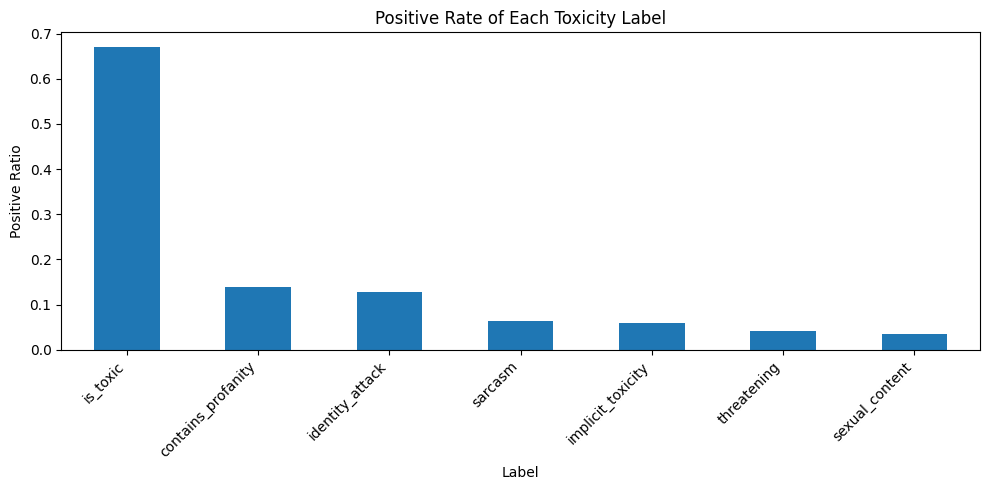

In [12]:
# =========================
# Cell 12: Plot Label Distribution
# =========================

ax = (
    train_df[LABELS]
    .mean()
    .sort_values(ascending=False)
    .plot(
        kind="bar",
        figsize=(10, 5)
    )
)

plt.title(
    "Positive Rate of Each Toxicity Label"
)

plt.ylabel(
    "Positive Ratio"
)

plt.xlabel(
    "Label"
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()
plt.show()

In [13]:
# =========================
# Cell 13: Number of Labels per Sample
# =========================

train_df["num_labels"] = (
    train_df[LABELS]
    .sum(axis=1)
)

label_per_sample = (
    train_df["num_labels"]
    .value_counts()
    .sort_index()
)

display(
    label_per_sample
    .rename("samples")
    .to_frame()
)

,samples
num_labels,
0,1077
1,1104
2,783
3,247
4,73
5,8


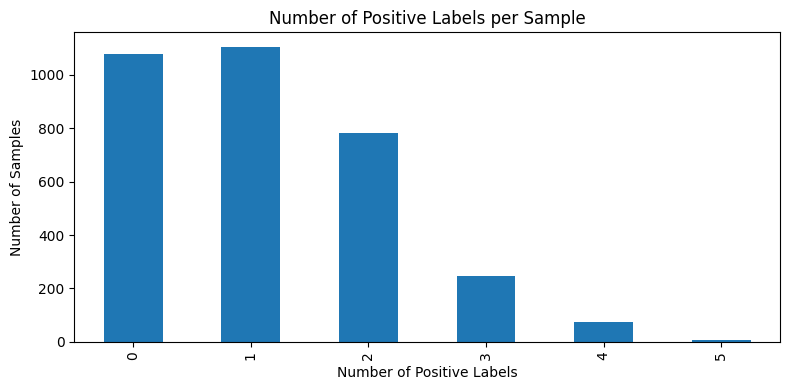

In [14]:
# =========================
# Cell 14: Plot Number of Labels per Sample
# =========================

ax = (
    train_df["num_labels"]
    .value_counts()
    .sort_index()
    .plot(
        kind="bar",
        figsize=(8, 4)
    )
)

plt.title(
    "Number of Positive Labels per Sample"
)

plt.xlabel(
    "Number of Positive Labels"
)

plt.ylabel(
    "Number of Samples"
)

plt.tight_layout()
plt.show()

In [15]:
# =========================
# Cell 15: Text Length Statistics
# =========================

train_df["char_length"] = (
    train_df["clean_text"]
    .str.len()
)

train_df["word_length"] = (
    train_df["clean_text"]
    .str.split()
    .str.len()
)

display(
    train_df[
        [
            "char_length",
            "word_length"
        ]
    ].describe(
        percentiles=[
            0.5,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
)

,char_length,word_length
count,3292.000000,3292.000000
mean,67.362394,12.085966
std,43.237083,7.390992
min,7.000000,2.000000
50%,56.000000,10.000000
75%,95.000000,17.000000
90%,127.000000,23.000000
95%,129.000000,24.000000
99%,144.000000,27.000000
max,645.000000,113.000000


In [16]:
# =========================
# Cell 16: Label Co-occurrence Matrix
# =========================

co_occurrence = (
    train_df[LABELS]
    .T
    .dot(
        train_df[LABELS]
    )
)

display(
    co_occurrence
)

,is_toxic,implicit_toxicity,sarcasm,contains_profanity,threatening,identity_attack,sexual_content
is_toxic,2203,192,203,461,135,424,113
implicit_toxicity,192,194,52,5,10,39,14
sarcasm,203,52,213,20,2,23,5
contains_profanity,461,5,20,461,53,116,71
threatening,135,10,2,53,135,31,18
identity_attack,424,39,23,116,31,424,55
sexual_content,113,14,5,71,18,55,113


In [17]:
# =========================
# Cell 17: Word TF-IDF
# =========================

word_vectorizer = TfidfVectorizer(
    analyzer="word",
    ngram_range=(1, 2),

    min_df=2,

    max_df=0.995,

    max_features=100000,

    sublinear_tf=True
)


X_train_word = (
    word_vectorizer
    .fit_transform(
        train_df["clean_text"]
    )
)

X_valid_word = (
    word_vectorizer
    .transform(
        valid_df["clean_text"]
    )
)


print(
    "Word TF-IDF train shape:",
    X_train_word.shape
)

Word TF-IDF train shape: (3292, 5925)


In [18]:
# =========================
# Cell 18: Character TF-IDF
# =========================

char_vectorizer = TfidfVectorizer(
    analyzer="char_wb",

    ngram_range=(3, 5),

    min_df=2,

    max_features=150000,

    sublinear_tf=True
)


X_train_char = (
    char_vectorizer
    .fit_transform(
        train_df["clean_text"]
    )
)

X_valid_char = (
    char_vectorizer
    .transform(
        valid_df["clean_text"]
    )
)


print(
    "Character TF-IDF train shape:",
    X_train_char.shape
)

Character TF-IDF train shape: (3292, 32202)


In [21]:
# =========================
# Cell 19: Combine Features
# =========================

X_train = hstack(
    [
        X_train_word,
        X_train_char
    ],
    format="csr"
)

X_valid = hstack(
    [
        X_valid_word,
        X_valid_char
    ],
    format="csr"
)

# Make independent writable CSR matrices.
# This avoids scipy/joblib problems with read-only sparse arrays.
X_train = X_train.copy()
X_valid = X_valid.copy()

# Ensure canonical CSR structure
X_train.sum_duplicates()
X_train.sort_indices()

X_valid.sum_duplicates()
X_valid.sort_indices()

# float64 is safe for LogisticRegression
X_train = X_train.astype(np.float64)
X_valid = X_valid.astype(np.float64)


y_train = (
    train_df[LABELS]
    .to_numpy(dtype=np.int32)
)

y_valid = (
    valid_df[LABELS]
    .to_numpy(dtype=np.int32)
)


print("X_train :", X_train.shape)
print("X_valid :", X_valid.shape)

print("y_train :", y_train.shape)
print("y_valid :", y_valid.shape)

print("\nSparse format:", X_train.getformat())
print("Data dtype   :", X_train.dtype)
print("Target dtype :", y_train.dtype)

print("\nTrain non-zero features:", X_train.nnz)
print("Valid non-zero features:", X_valid.nnz)

X_train : (3292, 38127)
X_valid : (500, 38127)
y_train : (3292, 7)
y_valid : (500, 7)

Sparse format: csr
Data dtype   : float64
Target dtype : int32

Train non-zero features: 407727
Valid non-zero features: 59564


In [22]:
# =========================
# Cell 20: Train Logistic Regression
# =========================

base_model = LogisticRegression(
    C=4.0,
    max_iter=2000,
    class_weight="balanced",
    solver="liblinear",
    random_state=SEED
)

# IMPORTANT:
# n_jobs=1 avoids joblib/loky multiprocessing problems
# with sparse matrices in some Python 3.13 environments.
model = OneVsRestClassifier(
    base_model,
    n_jobs=1
)

model.fit(
    X_train,
    y_train
)

print("Training completed successfully.")

Training completed successfully.


In [23]:
# =========================
# Cell 20: Train One Model Per Label
# =========================

models = {}

for i, label in enumerate(LABELS):

    print(
        f"[{i + 1}/{len(LABELS)}] "
        f"Training: {label}"
    )

    clf = LogisticRegression(
        C=4.0,
        max_iter=2000,
        class_weight="balanced",
        solver="liblinear",
        random_state=SEED
    )

    clf.fit(
        X_train,
        y_train[:, i]
    )

    models[label] = clf


print("\nAll models trained successfully.")

[1/7] Training: is_toxic
[2/7] Training: implicit_toxicity
[3/7] Training: sarcasm
[4/7] Training: contains_profanity
[5/7] Training: threatening
[6/7] Training: identity_attack
[7/7] Training: sexual_content

All models trained successfully.


In [24]:
valid_probabilities = model.predict_proba(X_valid)

In [25]:
# =========================
# Cell 21: Validation Probabilities
# =========================

valid_probabilities = np.column_stack(
    [
        models[label]
        .predict_proba(X_valid)[:, 1]

        for label in LABELS
    ]
)


print(
    "Validation probability shape:",
    valid_probabilities.shape
)

Validation probability shape: (500, 7)


In [28]:
# =========================
# Cell 22: Merge Train + Validation
# =========================

full_train_df = pd.concat(
    [
        train_df[["ID", "clean_text"] + LABELS],
        valid_df[["ID", "clean_text"] + LABELS]
    ],
    ignore_index=True
)

print("Full training shape:", full_train_df.shape)
display(full_train_df.head())

Full training shape: (3792, 9)


,ID,clean_text,is_toxic,implicit_toxicity,sarcasm,contains_profanity,threatening,identity_attack,sexual_content
0,BICH_0002,"""অতি ভক্তি চোরের লক্ষণ"" এর মতো হয়ে গেল",0,0,0,0,0,0,0
1,BICH_0004,Fazil meye and chutia cele,1,0,0,1,0,0,0
2,BICH_0005,মিথ্যা কথা ওর বাপ রে মানুষ বলে শাহরিয়ার কবির ...,1,1,1,0,0,0,0
3,BICH_0008,gf ভালো লাগে না খালি সন্দেহ করে টিক মতো মরছি ক...,0,0,0,0,0,0,0
4,BICH_0009,জোভানের নাটক... সোফা কবীর ওরফে মরগি কবীর এর মহ...,1,1,0,0,0,0,0


In [29]:
# =========================
# Cell 23: Final Word TF-IDF
# =========================

final_word_vectorizer = TfidfVectorizer(
    analyzer="word",
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.995,
    max_features=100000,
    sublinear_tf=True
)

X_full_word = final_word_vectorizer.fit_transform(
    full_train_df["clean_text"]
)

X_test_word = final_word_vectorizer.transform(
    test_df["clean_text"]
)

print("X_full_word:", X_full_word.shape)
print("X_test_word:", X_test_word.shape)

X_full_word: (3792, 7072)
X_test_word: (1000, 7072)


In [30]:
# =========================
# Cell 24: Final Character TF-IDF
# =========================

final_char_vectorizer = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3, 5),
    min_df=2,
    max_features=150000,
    sublinear_tf=True
)

X_full_char = final_char_vectorizer.fit_transform(
    full_train_df["clean_text"]
)

X_test_char = final_char_vectorizer.transform(
    test_df["clean_text"]
)

print("X_full_char:", X_full_char.shape)
print("X_test_char:", X_test_char.shape)

X_full_char: (3792, 35325)
X_test_char: (1000, 35325)


In [31]:
# =========================
# Cell 25: Final Feature Matrix
# =========================

X_full = hstack(
    [
        X_full_word,
        X_full_char
    ],
    format="csr"
)

X_test = hstack(
    [
        X_test_word,
        X_test_char
    ],
    format="csr"
)

X_full = X_full.copy()
X_test = X_test.copy()

X_full.sum_duplicates()
X_full.sort_indices()

X_test.sum_duplicates()
X_test.sort_indices()

X_full = X_full.astype(np.float64)
X_test = X_test.astype(np.float64)

y_full = (
    full_train_df[LABELS]
    .to_numpy(dtype=np.int32)
)

print("X_full:", X_full.shape)
print("X_test:", X_test.shape)
print("y_full:", y_full.shape)

X_full: (3792, 42397)
X_test: (1000, 42397)
y_full: (3792, 7)


In [32]:
# =========================
# Cell 26: Train Final Models
# =========================

final_models = {}

for i, label in enumerate(LABELS):

    print(
        f"[{i + 1}/{len(LABELS)}] "
        f"Training final model: {label}"
    )

    clf = LogisticRegression(
        C=4.0,
        max_iter=2000,
        class_weight="balanced",
        solver="liblinear",
        random_state=SEED
    )

    clf.fit(
        X_full,
        y_full[:, i]
    )

    final_models[label] = clf

print("\nAll final models trained successfully.")

[1/7] Training final model: is_toxic
[2/7] Training final model: implicit_toxicity
[3/7] Training final model: sarcasm
[4/7] Training final model: contains_profanity
[5/7] Training final model: threatening
[6/7] Training final model: identity_attack
[7/7] Training final model: sexual_content

All final models trained successfully.


In [33]:
# =========================
# Cell 27: Test Probabilities
# =========================

test_probabilities = np.column_stack(
    [
        final_models[label]
        .predict_proba(X_test)[:, 1]

        for label in LABELS
    ]
)

print("Test probability shape:", test_probabilities.shape)

Test probability shape: (1000, 7)


In [34]:
# =========================
# Cell 28: Apply Thresholds
# =========================

if "best_thresholds" not in globals():
    best_thresholds = np.array(
        [0.50] * len(LABELS)
    )

print("Thresholds:")
for label, threshold in zip(LABELS, best_thresholds):
    print(f"{label:25s}: {threshold:.2f}")

test_predictions = (
    test_probabilities
    >=
    best_thresholds.reshape(1, -1)
).astype(int)

Thresholds:
is_toxic                 : 0.50
implicit_toxicity        : 0.50
sarcasm                  : 0.50
contains_profanity       : 0.50
threatening              : 0.50
identity_attack          : 0.50
sexual_content           : 0.50


In [35]:
# =========================
# Cell 29: Create Submission
# =========================

submission = pd.DataFrame({
    "ID": test_df["ID"].values
})

for i, label in enumerate(LABELS):
    submission[label] = test_predictions[:, i]

submission = submission[
    ["ID"] + LABELS
]

display(submission.head(20))

,ID,is_toxic,implicit_toxicity,sarcasm,contains_profanity,threatening,identity_attack,sexual_content
0,BICH_0003,0,0,0,0,0,0,0
1,BICH_0006,1,0,0,0,0,0,0
2,BICH_0007,1,0,0,0,0,0,0
3,BICH_0011,1,0,0,0,0,0,0
4,BICH_0012,0,0,0,0,0,0,0
5,BICH_0013,1,0,0,0,0,0,0
6,BICH_0015,1,0,0,0,0,1,0
7,BICH_0017,0,0,0,0,0,0,0
8,BICH_0018,0,0,0,0,0,1,0
9,BICH_0023,1,0,1,0,0,0,0


In [36]:
# =========================
# Cell 30: Validate and Save Submission
# =========================

assert len(submission) == len(test_df)

assert list(submission.columns) == [
    "ID",
    "is_toxic",
    "implicit_toxicity",
    "sarcasm",
    "contains_profanity",
    "threatening",
    "identity_attack",
    "sexual_content"
]

for label in LABELS:
    assert set(
        submission[label].unique()
    ).issubset({0, 1})

submission.to_csv(
    "submission.csv",
    index=False
)

print("submission.csv created successfully.")

submission.csv created successfully.


In [38]:
!pip uninstall -y bitsandbytes

Found existing installation: bitsandbytes 0.49.1
Uninstalling bitsandbytes-0.49.1:
  Successfully uninstalled bitsandbytes-0.49.1


In [39]:
import os
import gc
import copy
import random

import numpy as np
import pandas as pd

import torch
from torch.utils.data import Dataset, DataLoader

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    get_linear_schedule_with_warmup,
)

from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    classification_report,
)

from tqdm.auto import tqdm

In [40]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA GeForce RTX 5090


In [41]:
LABELS = [
    "is_toxic",
    "implicit_toxicity",
    "sarcasm",
    "contains_profanity",
    "threatening",
    "identity_attack",
    "sexual_content",
]

NUM_LABELS = len(LABELS)

print("Number of labels:", NUM_LABELS)

Number of labels: 7


In [42]:
MODEL_NAME = "csebuetnlp/banglabert"

In [43]:
print("Selected model:", MODEL_NAME)

Selected model: csebuetnlp/banglabert


In [44]:
MAX_LENGTH = 128

TRAIN_BATCH_SIZE = 16
VALID_BATCH_SIZE = 32

EPOCHS = 5

LEARNING_RATE = 2e-5

WEIGHT_DECAY = 0.01

WARMUP_RATIO = 0.10

In [45]:
TRAIN_BATCH_SIZE = 8

In [46]:
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

print(
    "Tokenizer:",
    tokenizer.__class__.__name__
)

config.json:   0%|          | 0.00/586 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/119 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Tokenizer: BertTokenizer


In [47]:
class ToxicityDataset(Dataset):

    def __init__(
        self,
        dataframe,
        tokenizer,
        max_length,
        labels=None
    ):

        self.texts = (
            dataframe["clean_text"]
            .fillna("")
            .astype(str)
            .tolist()
        )

        self.tokenizer = tokenizer

        self.max_length = max_length

        self.labels = None

        if labels is not None:

            self.labels = (
                dataframe[labels]
                .values
                .astype(np.float32)
            )


    def __len__(self):

        return len(self.texts)


    def __getitem__(self, index):

        text = self.texts[index]

        encoding = self.tokenizer(
            text,

            truncation=True,

            max_length=self.max_length,

            padding="max_length",

            return_tensors="pt"
        )


        item = {
            key: value.squeeze(0)
            for key, value
            in encoding.items()
        }


        if self.labels is not None:

            item["labels"] = torch.tensor(
                self.labels[index],
                dtype=torch.float32
            )


        return item

In [48]:
dtype=torch.float32

In [49]:
train_dataset = ToxicityDataset(
    dataframe=train_df,
    tokenizer=tokenizer,
    max_length=MAX_LENGTH,
    labels=LABELS
)


valid_dataset = ToxicityDataset(
    dataframe=valid_df,
    tokenizer=tokenizer,
    max_length=MAX_LENGTH,
    labels=LABELS
)


test_dataset = ToxicityDataset(
    dataframe=test_df,
    tokenizer=tokenizer,
    max_length=MAX_LENGTH,
    labels=None
)


print(
    "Train:",
    len(train_dataset)
)

print(
    "Validation:",
    len(valid_dataset)
)

print(
    "Test:",
    len(test_dataset)
)

Train: 3292
Validation: 500
Test: 1000


In [50]:
train_loader = DataLoader(
    train_dataset,

    batch_size=TRAIN_BATCH_SIZE,

    shuffle=True,

    num_workers=0,

    pin_memory=torch.cuda.is_available()
)


valid_loader = DataLoader(
    valid_dataset,

    batch_size=VALID_BATCH_SIZE,

    shuffle=False,

    num_workers=0,

    pin_memory=torch.cuda.is_available()
)


test_loader = DataLoader(
    test_dataset,

    batch_size=VALID_BATCH_SIZE,

    shuffle=False,

    num_workers=0,

    pin_memory=torch.cuda.is_available()
)

In [51]:
num_workers=0

In [52]:
id2label = {
    i: label
    for i, label in enumerate(LABELS)
}

label2id = {
    label: i
    for i, label in enumerate(LABELS)
}


model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,

    num_labels=NUM_LABELS,

    id2label=id2label,

    label2id=label2id,

    problem_type="multi_label_classification"
)


model.to(DEVICE)

print(
    model.__class__.__name__
)

pytorch_model.bin:   0%|          | 0.00/443M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] ElectraForSequenceClassification LOAD REPORT from: csebuetnlp/banglabert
Key                                               | Status     | 
--------------------------------------------------+------------+-
discriminator_predictions.dense.bias              | UNEXPECTED | 
discriminator_predictions.dense_prediction.weight | UNEXPECTED | 
discriminator_predictions.dense.weight            | UNEXPECTED | 
discriminator_predictions.dense_prediction.bias   | UNEXPECTED | 
classifier.out_proj.weight                        | MISSING    | 
classifier.dense.weight                           | MISSING    | 
classifier.out_proj.bias                          | MISSING    | 
classifier.dense.bias                             | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


ElectraForSequenceClassification


model.safetensors:   0%|          | 0.00/443M [00:00<?, ?B/s]

In [53]:
optimizer = torch.optim.AdamW(
    model.parameters(),

    lr=LEARNING_RATE,

    weight_decay=WEIGHT_DECAY
)

In [54]:
TOTAL_STEPS = (
    len(train_loader)
    *
    EPOCHS
)


WARMUP_STEPS = int(
    TOTAL_STEPS
    *
    WARMUP_RATIO
)


scheduler = get_linear_schedule_with_warmup(
    optimizer,

    num_warmup_steps=WARMUP_STEPS,

    num_training_steps=TOTAL_STEPS
)


print(
    "Total steps:",
    TOTAL_STEPS
)

print(
    "Warmup steps:",
    WARMUP_STEPS
)

Total steps: 2060
Warmup steps: 206


In [55]:
def train_one_epoch(
    model,
    loader,
    optimizer,
    scheduler,
    device
):

    model.train()

    total_loss = 0.0


    progress_bar = tqdm(
        loader,
        desc="Training"
    )


    for batch in progress_bar:

        optimizer.zero_grad()


        batch = {
            key: value.to(device)
            for key, value
            in batch.items()
        }


        outputs = model(
            **batch
        )


        loss = outputs.loss


        loss.backward()


        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )


        optimizer.step()

        scheduler.step()


        total_loss += loss.item()


        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )


    average_loss = (
        total_loss
        /
        len(loader)
    )


    return average_loss

In [56]:
@torch.no_grad()
def evaluate_model(
    model,
    loader,
    device,
    threshold=0.50
):

    model.eval()


    total_loss = 0.0

    all_probabilities = []

    all_labels = []


    for batch in tqdm(
        loader,
        desc="Validation"
    ):

        labels = batch["labels"]


        batch = {
            key: value.to(device)
            for key, value
            in batch.items()
        }


        outputs = model(
            **batch
        )


        loss = outputs.loss

        logits = outputs.logits


        probabilities = torch.sigmoid(
            logits
        )


        total_loss += loss.item()


        all_probabilities.append(
            probabilities
            .cpu()
            .numpy()
        )


        all_labels.append(
            labels.numpy()
        )


    probabilities = np.vstack(
        all_probabilities
    )


    true_labels = np.vstack(
        all_labels
    ).astype(int)


    predictions = (
        probabilities >= threshold
    ).astype(int)


    macro_f1 = f1_score(
        true_labels,
        predictions,
        average="macro",
        zero_division=0
    )


    micro_f1 = f1_score(
        true_labels,
        predictions,
        average="micro",
        zero_division=0
    )


    weighted_f1 = f1_score(
        true_labels,
        predictions,
        average="weighted",
        zero_division=0
    )


    average_loss = (
        total_loss
        /
        len(loader)
    )


    return {
        "loss": average_loss,

        "macro_f1": macro_f1,

        "micro_f1": micro_f1,

        "weighted_f1": weighted_f1,

        "probabilities": probabilities,

        "labels": true_labels
    }

In [57]:
best_macro_f1 = -1

best_state_dict = None

history = []


for epoch in range(EPOCHS):

    print(
        f"\n{'=' * 60}"
    )

    print(
        f"Epoch {epoch + 1}/{EPOCHS}"
    )

    print(
        f"{'=' * 60}"
    )


    train_loss = train_one_epoch(
        model=model,

        loader=train_loader,

        optimizer=optimizer,

        scheduler=scheduler,

        device=DEVICE
    )


    val_results = evaluate_model(
        model=model,

        loader=valid_loader,

        device=DEVICE,

        threshold=0.50
    )


    print(
        f"\nTrain Loss : "
        f"{train_loss:.4f}"
    )

    print(
        f"Valid Loss : "
        f"{val_results['loss']:.4f}"
    )

    print(
        f"Macro F1   : "
        f"{val_results['macro_f1']:.4f}"
    )

    print(
        f"Micro F1   : "
        f"{val_results['micro_f1']:.4f}"
    )

    print(
        f"Weighted F1: "
        f"{val_results['weighted_f1']:.4f}"
    )


    history.append({
        "epoch": epoch + 1,

        "train_loss": train_loss,

        "valid_loss": val_results["loss"],

        "macro_f1": val_results["macro_f1"],

        "micro_f1": val_results["micro_f1"],

        "weighted_f1": val_results["weighted_f1"]
    })


    if (
        val_results["macro_f1"]
        >
        best_macro_f1
    ):

        best_macro_f1 = (
            val_results["macro_f1"]
        )

        best_state_dict = copy.deepcopy(
            model.state_dict()
        )

        print(
            "\n✓ New best model"
        )


Epoch 1/5


Training:   0%|          | 0/412 [00:00<?, ?it/s]

Validation:   0%|          | 0/16 [00:00<?, ?it/s]


Train Loss : 0.4045
Valid Loss : 0.2880
Macro F1   : 0.1403
Micro F1   : 0.6357
Weighted F1: 0.4954

✓ New best model

Epoch 2/5


Training:   0%|          | 0/412 [00:00<?, ?it/s]

...

Validation:   0%|          | 0/16 [00:00<?, ?it/s]


Train Loss : 0.2166
Valid Loss : 0.2687
Macro F1   : 0.2246
Micro F1   : 0.6421
Weighted F1: 0.5544

✓ New best model

Epoch 5/5


Training:   0%|          | 0/412 [00:00<?, ?it/s]

Validation:   0%|          | 0/16 [00:00<?, ?it/s]


Train Loss : 0.1968
Valid Loss : 0.2694
Macro F1   : 0.2313
Micro F1   : 0.6593
Weighted F1: 0.5700

✓ New best model


In [58]:
history_df = pd.DataFrame(
    history
)

display(
    history_df.round(4)
)

,epoch,train_loss,valid_loss,macro_f1,micro_f1,weighted_f1
0,1,0.4045,0.2880,0.1403,0.6357,0.4954
1,2,0.2709,0.2680,0.2219,0.6706,0.5686
2,3,0.2425,0.2650,0.2185,0.6627,0.5642
3,4,0.2166,0.2687,0.2246,0.6421,0.5544
4,5,0.1968,0.2694,0.2313,0.6593,0.5700


In [59]:
model.load_state_dict(
    best_state_dict
)

model.to(DEVICE)

print(
    "Best Macro F1:",
    round(best_macro_f1, 4)
)

Best Macro F1: 0.2313


In [60]:
val_results = evaluate_model(
    model=model,

    loader=valid_loader,

    device=DEVICE,

    threshold=0.50
)


valid_probabilities = (
    val_results["probabilities"]
)

y_valid_transformer = (
    val_results["labels"]
)


print(
    valid_probabilities.shape
)

Validation:   0%|          | 0/16 [00:00<?, ?it/s]

(500, 7)


In [61]:
def tune_thresholds(
    y_true,
    probabilities,
    labels
):

    threshold_grid = np.arange(
        0.10,
        0.91,
        0.02
    )


    best_thresholds = []

    results = []


    for i, label in enumerate(labels):

        best_threshold = 0.50

        best_score = -1


        for threshold in threshold_grid:

            predictions = (
                probabilities[:, i]
                >=
                threshold
            ).astype(int)


            score = f1_score(
                y_true[:, i],

                predictions,

                zero_division=0
            )


            if score > best_score:

                best_score = score

                best_threshold = threshold


        best_thresholds.append(
            best_threshold
        )


        results.append({
            "label": label,

            "threshold":
                best_threshold,

            "f1":
                best_score
        })


    return (
        np.array(
            best_thresholds
        ),

        pd.DataFrame(
            results
        )
    )

In [62]:
transformer_thresholds, threshold_df = tune_thresholds(
    y_valid_transformer,

    valid_probabilities,

    LABELS
)


display(
    threshold_df.round(4)
)

,label,threshold,f1
0,is_toxic,0.18,0.8130
1,implicit_toxicity,0.10,0.3438
2,sarcasm,0.12,0.3902
3,contains_profanity,0.40,0.7465
4,threatening,0.10,0.2857
5,identity_attack,0.16,0.3232
6,sexual_content,0.20,0.3030


In [63]:
valid_predictions_tuned = (
    valid_probabilities
    >=
    transformer_thresholds.reshape(
        1,
        -1
    )
).astype(int)


print(
    "Macro F1:",
    f1_score(
        y_valid_transformer,
        valid_predictions_tuned,
        average="macro",
        zero_division=0
    )
)


print(
    "Micro F1:",
    f1_score(
        y_valid_transformer,
        valid_predictions_tuned,
        average="micro",
        zero_division=0
    )
)

Macro F1: 0.45791952866319796
Micro F1: 0.6475349521707138


In [64]:
report = classification_report(
    y_valid_transformer,

    valid_predictions_tuned,

    target_names=LABELS,

    output_dict=True,

    zero_division=0
)


report_df = pd.DataFrame(
    report
).T


display(
    report_df.loc[
        LABELS,
        [
            "precision",
            "recall",
            "f1-score",
            "support"
        ]
    ].round(4)
)

,precision,recall,f1-score,support
is_toxic,0.7195,0.9343,0.8130,335.0
implicit_toxicity,0.3235,0.3667,0.3438,30.0
sarcasm,0.3200,0.5000,0.3902,32.0
contains_profanity,0.7361,0.7571,0.7465,70.0
threatening,0.2000,0.5000,0.2857,20.0
identity_attack,0.2388,0.5000,0.3232,64.0
sexual_content,0.3125,0.2941,0.3030,17.0


In [65]:
@torch.no_grad()
def predict_test(
    model,
    loader,
    device
):

    model.eval()

    probabilities = []


    for batch in tqdm(
        loader,
        desc="Test inference"
    ):

        batch = {
            key: value.to(device)
            for key, value
            in batch.items()
        }


        outputs = model(
            **batch
        )


        probs = torch.sigmoid(
            outputs.logits
        )


        probabilities.append(
            probs.cpu().numpy()
        )


    return np.vstack(
        probabilities
    )

In [66]:
test_probabilities = predict_test(
    model=model,

    loader=test_loader,

    device=DEVICE
)


print(
    test_probabilities.shape
)

Test inference:   0%|          | 0/32 [00:00<?, ?it/s]

(1000, 7)


In [67]:
test_predictions = (
    test_probabilities
    >=
    transformer_thresholds.reshape(
        1,
        -1
    )
).astype(int)

In [68]:
# =========================
# Cell 57: Create Transformer Submission
# =========================

transformer_submission = pd.DataFrame({
    "ID": test_df["ID"].values
})

for i, label in enumerate(LABELS):
    transformer_submission[label] = test_predictions[:, i]

transformer_submission = transformer_submission[
    ["ID"] + LABELS
]

display(transformer_submission.head(20))

,ID,is_toxic,implicit_toxicity,sarcasm,contains_profanity,threatening,identity_attack,sexual_content
0,BICH_0003,1,1,1,0,0,0,0
1,BICH_0006,1,0,0,0,0,0,0
2,BICH_0007,1,0,0,0,0,0,0
3,BICH_0011,1,0,0,0,0,0,0
4,BICH_0012,1,0,0,0,0,0,0
5,BICH_0013,1,0,0,0,0,0,0
6,BICH_0015,1,0,0,0,0,0,0
7,BICH_0017,1,0,0,0,0,0,0
8,BICH_0018,0,0,0,0,0,0,0
9,BICH_0023,1,0,0,0,0,0,0


In [69]:
# =========================
# Cell 58: Validate Submission Format
# =========================

assert len(transformer_submission) == len(test_df)

assert (
    transformer_submission["ID"].tolist()
    ==
    test_df["ID"].tolist()
)

assert list(transformer_submission.columns) == [
    "ID",
    "is_toxic",
    "implicit_toxicity",
    "sarcasm",
    "contains_profanity",
    "threatening",
    "identity_attack",
    "sexual_content",
]

for label in LABELS:
    assert set(
        transformer_submission[label].unique()
    ).issubset({0, 1})

print("Transformer submission format is valid.")

Transformer submission format is valid.


In [70]:
# =========================
# Cell 59: Save Submission
# =========================

TRANSFORMER_SUBMISSION_PATH = (
    f"submission_{MODEL_NAME.split('/')[-1]}.csv"
)

transformer_submission.to_csv(
    TRANSFORMER_SUBMISSION_PATH,
    index=False
)

print(
    "Saved:",
    TRANSFORMER_SUBMISSION_PATH
)

Saved: submission_banglabert.csv


In [71]:
# =========================
# Cell 60: Save Validation Results
# =========================

validation_summary = pd.DataFrame({
    "label": LABELS,
    "threshold": transformer_thresholds,
})

for i, label in enumerate(LABELS):

    validation_summary.loc[
        validation_summary["label"] == label,
        "precision"
    ] = precision_score(
        y_valid_transformer[:, i],
        valid_predictions_tuned[:, i],
        zero_division=0
    )

    validation_summary.loc[
        validation_summary["label"] == label,
        "recall"
    ] = recall_score(
        y_valid_transformer[:, i],
        valid_predictions_tuned[:, i],
        zero_division=0
    )

    validation_summary.loc[
        validation_summary["label"] == label,
        "f1"
    ] = f1_score(
        y_valid_transformer[:, i],
        valid_predictions_tuned[:, i],
        zero_division=0
    )

display(
    validation_summary.round(4)
)

,label,threshold,precision,recall,f1
0,is_toxic,0.18,0.7195,0.9343,0.8130
1,implicit_toxicity,0.10,0.3235,0.3667,0.3438
2,sarcasm,0.12,0.3200,0.5000,0.3902
3,contains_profanity,0.40,0.7361,0.7571,0.7465
4,threatening,0.10,0.2000,0.5000,0.2857
5,identity_attack,0.16,0.2388,0.5000,0.3232
6,sexual_content,0.20,0.3125,0.2941,0.3030


In [72]:
# =========================
# Cell 61: Overall Transformer Metrics
# =========================

macro_f1 = f1_score(
    y_valid_transformer,
    valid_predictions_tuned,
    average="macro",
    zero_division=0
)

micro_f1 = f1_score(
    y_valid_transformer,
    valid_predictions_tuned,
    average="micro",
    zero_division=0
)

weighted_f1 = f1_score(
    y_valid_transformer,
    valid_predictions_tuned,
    average="weighted",
    zero_division=0
)

samples_f1 = f1_score(
    y_valid_transformer,
    valid_predictions_tuned,
    average="samples",
    zero_division=0
)

print(f"Model       : {MODEL_NAME}")
print(f"Macro F1    : {macro_f1:.4f}")
print(f"Micro F1    : {micro_f1:.4f}")
print(f"Weighted F1 : {weighted_f1:.4f}")
print(f"Samples F1  : {samples_f1:.4f}")

Model       : csebuetnlp/banglabert
Macro F1    : 0.4579
Micro F1    : 0.6475
Weighted F1 : 0.6672
Samples F1  : 0.5144


In [73]:
# =========================
# Cell 62: Store Model Result
# =========================

if "MODEL_RESULTS" not in globals():
    MODEL_RESULTS = []

MODEL_RESULTS.append({
    "model": MODEL_NAME,
    "macro_f1": macro_f1,
    "micro_f1": micro_f1,
    "weighted_f1": weighted_f1,
    "samples_f1": samples_f1,
})

results_df = pd.DataFrame(MODEL_RESULTS)

display(
    results_df.sort_values(
        "macro_f1",
        ascending=False
    ).round(4)
)

,model,macro_f1,micro_f1,weighted_f1,samples_f1
0,csebuetnlp/banglabert,0.4579,0.6475,0.6672,0.5144


In [74]:
# =========================
# Cell 63: Save Validation Probabilities
# =========================

model_short_name = MODEL_NAME.split("/")[-1]

validation_probability_df = pd.DataFrame({
    "ID": valid_df["ID"].values
})

for i, label in enumerate(LABELS):

    validation_probability_df[
        f"{label}_prob"
    ] = valid_probabilities[:, i]

validation_probability_df.to_csv(
    f"validation_probs_{model_short_name}.csv",
    index=False
)

print(
    f"Saved validation_probs_{model_short_name}.csv"
)

Saved validation_probs_banglabert.csv


In [75]:
# =========================
# Cell 64: Save Test Probabilities
# =========================

test_probability_df = pd.DataFrame({
    "ID": test_df["ID"].values
})

for i, label in enumerate(LABELS):

    test_probability_df[
        f"{label}_prob"
    ] = test_probabilities[:, i]

test_probability_df.to_csv(
    f"test_probs_{model_short_name}.csv",
    index=False
)

print(
    f"Saved test_probs_{model_short_name}.csv"
)

Saved test_probs_banglabert.csv


In [76]:
# =========================
# Cell 65: Save Fine-Tuned Model
# =========================

SAVE_DIR = f"./best_{model_short_name}"

os.makedirs(
    SAVE_DIR,
    exist_ok=True
)

model.save_pretrained(
    SAVE_DIR
)

tokenizer.save_pretrained(
    SAVE_DIR
)

print(
    "Model saved to:",
    SAVE_DIR
)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved to: ./best_banglabert


In [77]:
# =========================
# Cell 66: Validation Prediction Table
# =========================

validation_prediction_df = valid_df[
    ["ID", "text"]
].copy()

for i, label in enumerate(LABELS):

    validation_prediction_df[
        f"true_{label}"
    ] = y_valid_transformer[:, i]

    validation_prediction_df[
        f"pred_{label}"
    ] = valid_predictions_tuned[:, i]

    validation_prediction_df[
        f"prob_{label}"
    ] = valid_probabilities[:, i]

display(
    validation_prediction_df.head()
)

,ID,text,true_is_toxic,pred_is_toxic,prob_is_toxic,true_implicit_toxicity,pred_implicit_toxicity,prob_implicit_toxicity,true_sarcasm,pred_sarcasm,...,prob_contains_profanity,true_threatening,pred_threatening,prob_threatening,true_identity_attack,pred_identity_attack,prob_identity_attack,true_sexual_content,pred_sexual_content,prob_sexual_content
0,BICH_0036,Pagol ra pama jala ki,0,1,0.954825,0,0,0.014152,0,0,...,0.024418,0,0,0.009153,0,0,0.064620,0,0,0.005161
1,BICH_0042,মেয়ে রা আমরা এমনই,0,0,0.139927,0,0,0.058991,0,0,...,0.011185,0,0,0.019914,0,0,0.029647,0,0,0.010386
2,BICH_0044,আজকে আমরা মোন ভালো নেই,0,0,0.104942,0,0,0.075490,0,0,...,0.010150,0,0,0.022542,0,0,0.029449,0,0,0.011839
3,BICH_0045,"চেবা করিম ফালতু, ওর নাটক দেখে কে?",1,1,0.964065,0,0,0.014468,0,0,...,0.025917,0,0,0.010282,0,0,0.087186,0,0,0.005646
4,BICH_0049,"আমরা সিলেটিরা কত চালাক, সুযোগ পাইলেই কুপা ছামছ...",1,1,0.926046,1,0,0.052530,1,0,...,0.472118,1,1,0.149585,1,1,0.424732,0,0,0.110662


In [78]:
# =========================
# Cell 67: Samples With Any Wrong Label
# =========================

error_mask = (
    y_valid_transformer
    !=
    valid_predictions_tuned
).any(axis=1)

transformer_errors = (
    validation_prediction_df[
        error_mask
    ]
    .copy()
)

print(
    "Samples with at least one incorrect label:",
    len(transformer_errors)
)

display(
    transformer_errors.head(30)
)

Samples with at least one incorrect label: 316


,ID,text,true_is_toxic,pred_is_toxic,prob_is_toxic,true_implicit_toxicity,pred_implicit_toxicity,prob_implicit_toxicity,true_sarcasm,pred_sarcasm,...,prob_contains_profanity,true_threatening,pred_threatening,prob_threatening,true_identity_attack,pred_identity_attack,prob_identity_attack,true_sexual_content,pred_sexual_content,prob_sexual_content
0,BICH_0036,Pagol ra pama jala ki,0,1,0.954825,0,0,0.014152,0,0,...,0.024418,0,0,0.009153,0,0,0.064620,0,0,0.005161
4,BICH_0049,"আমরা সিলেটিরা কত চালাক, সুযোগ পাইলেই কুপা ছামছ...",1,1,0.926046,1,0,0.052530,1,0,...,0.472118,1,1,0.149585,1,1,0.424732,0,0,0.110662
8,BICH_0093,ঠিক করেছে তোদের কে এইভাবেই শিক্ষা দেয়া উচিত ন...,1,1,0.899462,1,0,0.040980,0,0,...,0.010424,0,0,0.017471,1,0,0.100124,0,0,0.007834
9,BICH_0094,ভাই এইটা এত নিচে আইলো কেমনে,0,1,0.868864,0,0,0.031010,0,0,...,0.008904,0,0,0.010677,0,0,0.062173,0,0,0.005918
11,BICH_0108,তুই নাইটি পর কিন্তু নোংরামি বন্ধ কর হারামজাদা,1,1,0.944680,0,0,0.021870,0,0,...,0.895611,0,1,0.132247,1,1,0.343863,1,0,0.146261
13,BICH_0127,এদের হাতে ডান্ডাবেরি ও কমরে দরি নাই কেন??? জবা...,0,1,0.704104,0,0,0.055767,0,0,...,0.017255,0,0,0.029158,0,0,0.115226,0,0,0.013201
15,BICH_0144,এরা মনে হয় পার্কে গেছে ফটোশুট করতে। এদের মাজা...,1,1,0.736891,0,1,0.104793,1,1,...,0.009549,1,0,0.030014,0,0,0.102986,0,0,0.017062
16,BICH_0152,দোতলার চাঁদ দশে নিচ তলায় পড়ে গেছে এক জায়গার...,0,1,0.251036,0,1,0.175256,0,1,...,0.013291,0,0,0.032893,0,0,0.067358,0,0,0.029596
18,BICH_0163,সব পাগল এক জায়গায়,1,1,0.947266,1,0,0.024168,0,0,...,0.014955,0,0,0.011017,0,0,0.067694,0,0,0.006242
20,BICH_0194,জায়েদ খান যেমন তারছিরা পাগলা তার বক্তব্য পাগলা,1,1,0.965320,0,0,0.041845,0,0,...,0.034700,0,0,0.030952,0,1,0.191273,0,0,0.019094


In [79]:
# =========================
# Cell 68: Number of Errors Per Sample
# =========================

transformer_errors[
    "num_wrong_labels"
] = (
    y_valid_transformer[error_mask]
    !=
    valid_predictions_tuned[error_mask]
).sum(axis=1)

transformer_errors = (
    transformer_errors
    .sort_values(
        "num_wrong_labels",
        ascending=False
    )
)

display(
    transformer_errors[
        [
            "ID",
            "text",
            "num_wrong_labels"
        ]
    ].head(30)
)

,ID,text,num_wrong_labels
489,BICH_4735,আমরা নারি হবে না আমি নারি হবে,7
491,BICH_4742,তোর জুতা পেটা করা উচিত মদ্দা মাগি। ছেঁড়া,5
370,BICH_3532,Tor maa ar baba ek bejonma ke jonmo diyeche se...,5
447,BICH_4376,"পেট এইরকম ২ভাগ কেনো,?",5
422,BICH_4148,সামনের বস্তা টা নিচে রেখে দিন তাহলেই তো আর এত ...,4
402,BICH_3961,গু মুখি আর তুই হিজরা মুখি,4
160,BICH_1412,"ধোন বলেছেন ভাই সেই হইছে। নতুন ইস্যু নিয়ে, পাব...",4
368,BICH_3463,##কোথায় এখন বোকাচোদা সকল সেকুলাররা##,4
466,BICH_4562,Abe ........ Vai tui ki meye nighti pore ghurb...,4
4,BICH_0049,"আমরা সিলেটিরা কত চালাক, সুযোগ পাইলেই কুপা ছামছ...",3


In [80]:
# =========================
# Cell 69: Inspect Errors for One Label
# =========================

LABEL_TO_INSPECT = "implicit_toxicity"

label_index = LABELS.index(
    LABEL_TO_INSPECT
)

label_error_mask = (
    y_valid_transformer[:, label_index]
    !=
    valid_predictions_tuned[:, label_index]
)

label_errors = valid_df[
    ["ID", "text"]
].loc[
    label_error_mask
].copy()

label_errors["true"] = (
    y_valid_transformer[
        label_error_mask,
        label_index
    ]
)

label_errors["pred"] = (
    valid_predictions_tuned[
        label_error_mask,
        label_index
    ]
)

label_errors["probability"] = (
    valid_probabilities[
        label_error_mask,
        label_index
    ]
)

print(
    "Label:",
    LABEL_TO_INSPECT
)

print(
    "Number of mistakes:",
    len(label_errors)
)

display(
    label_errors.head(30)
)

Label: implicit_toxicity
Number of mistakes: 42


,ID,text,true,pred,probability
4,BICH_0049,"আমরা সিলেটিরা কত চালাক, সুযোগ পাইলেই কুপা ছামছ...",1,0,0.052530
8,BICH_0093,ঠিক করেছে তোদের কে এইভাবেই শিক্ষা দেয়া উচিত ন...,1,0,0.040980
15,BICH_0144,এরা মনে হয় পার্কে গেছে ফটোশুট করতে। এদের মাজা...,0,1,0.104793
16,BICH_0152,দোতলার চাঁদ দশে নিচ তলায় পড়ে গেছে এক জায়গার...,0,1,0.175256
18,BICH_0163,সব পাগল এক জায়গায়,1,0,0.024168
30,BICH_0243,যেটা করেছে ঠিক করেছে। পেছন দোলানো বগল দেখানো ক...,1,0,0.094178
33,BICH_0267,আমরা এমন একটা উন্নত রাষ্ট্রে আছি। যেখানে হেলিক...,0,1,0.133991
34,BICH_0276,ঠিক করেছে। সমাজের কীট তোরা,1,0,0.051527
37,BICH_0309,Maruti M Biswas সাজানো গোছানো চোরের বাগান টা ছ...,1,0,0.065008
52,BICH_0443,লিডার কম ডিলার বেশি লাগে,1,0,0.079330


In [81]:
# =========================
# Cell 70: Transformer Models to Benchmark
# =========================

MODEL_CANDIDATES = {
    "BanglaBERT":
        "csebuetnlp/banglabert",

    "BanglishBERT":
        "csebuetnlp/banglishbert",

    "mBERT":
        "google-bert/bert-base-multilingual-cased",

    "XLM-R":
        "FacebookAI/xlm-roberta-base",
}

for name, checkpoint in MODEL_CANDIDATES.items():

    print(
        f"{name:15s} -> {checkpoint}"
    )

BanglaBERT      -> csebuetnlp/banglabert
BanglishBERT    -> csebuetnlp/banglishbert
mBERT           -> google-bert/bert-base-multilingual-cased
XLM-R           -> FacebookAI/xlm-roberta-base
